[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch09_nlp.ipynb)

# 9장 딥러닝 자연어 처리 · 실습 노트북
『딥러닝 응용 — 보고, 읽고, 설명하는 딥러닝』

1. 텍스트를 토큰으로 나누고 빈도 세기 (9.2~9.3절)
2. 정수 인코딩과 원-핫 인코딩 (9.4절)
3. 임베딩 층의 입출력 모양 (9.5절)
4. 실습 ①: 짧은 한국어 리뷰 긍정/부정 분류 (9.7~9.9절)
5. 실습 ②: 로이터 뉴스 46개 주제 분류 (9.10절)

CPU 런타임에서 실습 예시 답안까지 모두 실행하면 15분쯤 걸립니다.

## 1. 텍스트를 토큰으로 나누고 빈도 세기

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from numpy import array
from tensorflow.keras.preprocessing.text import text_to_word_sequence, Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing import sequence
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Embedding, LSTM, GlobalAveragePooling1D, TextVectorization
from tensorflow.keras.datasets import reuters
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)   # 실행할 때마다 같은 결과가 나오도록 시드 고정

In [2]:
# 전처리할 텍스트를 정합니다.
text = '해보지 않으면 해낼 수 없다'

# 해당 텍스트를 토큰화합니다.
result = text_to_word_sequence(text)
print("\n원문:\n", text)
print("\n토큰화:\n", result)


원문:
 해보지 않으면 해낼 수 없다

토큰화:
 ['해보지', '않으면', '해낼', '수', '없다']


In [3]:
# 전처리하려는 세 개의 문장을 정합니다.
docs = ['먼저 텍스트의 각 단어를 나누어 토큰화합니다.',
        '텍스트의 단어로 토큰화해야 딥러닝에서 인식됩니다.',
        '토큰화한 결과는 딥러닝에서 사용할 수 있습니다.',
        ]

# 토큰화 함수를 이용해 전처리하는 과정입니다.
token = Tokenizer()             # 토큰화 함수 지정
token.fit_on_texts(docs)        # 토큰화 함수에 문장 적용하기

# 각 옵션에 맞춰 단어의 빈도 수를 계산한 결과를 출력합니다.
print("\n단어 카운트:\n", token.word_counts)
print("\n문장 카운트: ", token.document_count)
print("\n각 단어가 몇 개의 문장에 포함되어 있는가:\n", token.word_docs)
print("\n각 단어에 매겨진 인덱스 값:\n", token.word_index)


단어 카운트:
 OrderedDict({'먼저': 1, '텍스트의': 2, '각': 1, '단어를': 1, '나누어': 1, '토큰화합니다': 1, '단어로': 1, '토큰화해야': 1, '딥러닝에서': 2, '인식됩니다': 1, '토큰화한': 1, '결과는': 1, '사용할': 1, '수': 1, '있습니다': 1})

문장 카운트:  3

각 단어가 몇 개의 문장에 포함되어 있는가:
 defaultdict(<class 'int'>, {'나누어': 1, '텍스트의': 2, '단어를': 1, '먼저': 1, '토큰화합니다': 1, '각': 1, '인식됩니다': 1, '단어로': 1, '딥러닝에서': 2, '토큰화해야': 1, '있습니다': 1, '사용할': 1, '수': 1, '결과는': 1, '토큰화한': 1})

각 단어에 매겨진 인덱스 값:
 {'텍스트의': 1, '딥러닝에서': 2, '먼저': 3, '각': 4, '단어를': 5, '나누어': 6, '토큰화합니다': 7, '단어로': 8, '토큰화해야': 9, '인식됩니다': 10, '토큰화한': 11, '결과는': 12, '사용할': 13, '수': 14, '있습니다': 15}


단어별 빈도를 문장마다 세어 벡터로 만든 것이 Bag-of-Words입니다. `texts_to_matrix(mode='count')`로 확인해 볼 수 있습니다.
첫 열(인덱스 0)은 쓰지 않는 자리라 항상 0입니다.

In [4]:
bow = token.texts_to_matrix(docs, mode='count')
print(bow.shape)
print(bow.astype(int))

(3, 16)
[[0 1 0 1 1 1 1 1 0 0 0 0 0 0 0 0]
 [0 1 1 0 0 0 0 0 1 1 1 0 0 0 0 0]
 [0 0 1 0 0 0 0 0 0 0 0 1 1 1 1 1]]


## 2. 정수 인코딩과 원-핫 인코딩

In [5]:
text = "오랫동안 꿈꾸는 이는 그 꿈을 닮아간다"

token = Tokenizer()
token.fit_on_texts([text])
print(token.word_index)

{'오랫동안': 1, '꿈꾸는': 2, '이는': 3, '그': 4, '꿈을': 5, '닮아간다': 6}


In [6]:
x = token.texts_to_sequences([text])
print(x)

[[1, 2, 3, 4, 5, 6]]


In [7]:
# 인덱스 수에 하나를 추가해서 원-핫 인코딩 배열 만들기
word_size = len(token.word_index) + 1
x = to_categorical(x, num_classes=word_size)
print(x)

[[[0. 1. 0. 0. 0. 0. 0.]
  [0. 0. 1. 0. 0. 0. 0.]
  [0. 0. 0. 1. 0. 0. 0.]
  [0. 0. 0. 0. 1. 0. 0.]
  [0. 0. 0. 0. 0. 1. 0.]
  [0. 0. 0. 0. 0. 0. 1.]]]


## 3. 임베딩 층의 입출력 모양

In [8]:
# 단어 16개짜리 사전의 각 단어를 길이 4의 밀집 벡터로 바꾸는 층
emb = Embedding(16, 4)
out = emb(np.array([[1, 5, 9]]))      # 문장 1개, 단어 3개
print(out.shape)                      # (문장 수, 단어 수, 임베딩 크기)
print('파라미터 수:', emb.count_params(), '= 16 × 4')

(1, 3, 4)
파라미터 수: 64 = 16 × 4


## 4. 실습 ①: 짧은 한국어 리뷰 긍정/부정 분류

In [9]:
# 텍스트 리뷰 자료를 지정합니다.
docs = ['너무 재밌네요','최고예요','참 잘 만든 영화예요','추천하고 싶은 영화입니다.','한 번 더 보고싶네요',
        '글쎄요','별로예요','생각보다 지루하네요','연기가 어색해요','재미없어요']

# 긍정 리뷰는 1, 부정 리뷰는 0으로 클래스를 지정합니다.
classes = array([1,1,1,1,1,0,0,0,0,0])

# 토큰화
token = Tokenizer()
token.fit_on_texts(docs)
print(token.word_index)

{'너무': 1, '재밌네요': 2, '최고예요': 3, '참': 4, '잘': 5, '만든': 6, '영화예요': 7, '추천하고': 8, '싶은': 9, '영화입니다': 10, '한': 11, '번': 12, '더': 13, '보고싶네요': 14, '글쎄요': 15, '별로예요': 16, '생각보다': 17, '지루하네요': 18, '연기가': 19, '어색해요': 20, '재미없어요': 21}


In [10]:
x = token.texts_to_sequences(docs)
print("\n리뷰 텍스트, 토큰화 결과:\n", x)


리뷰 텍스트, 토큰화 결과:
 [[1, 2], [3], [4, 5, 6, 7], [8, 9, 10], [11, 12, 13, 14], [15], [16], [17, 18], [19, 20], [21]]


In [11]:
# 패딩, 서로 다른 길이의 데이터를 4로 맞추어 줍니다.
padded_x = pad_sequences(x, 4)
print("\n패딩 결과:\n", padded_x)


패딩 결과:
 [[ 0  0  1  2]
 [ 0  0  0  3]
 [ 4  5  6  7]
 [ 0  8  9 10]
 [11 12 13 14]
 [ 0  0  0 15]
 [ 0  0  0 16]
 [ 0  0 17 18]
 [ 0  0 19 20]
 [ 0  0  0 21]]


In [12]:
# 임베딩에 입력될 단어의 수를 지정합니다.
word_size = len(token.word_index) + 1

# 단어 임베딩을 포함하여 딥러닝 모델을 만들고 결과를 출력합니다.
model = Sequential()
model.add(Embedding(word_size, 8, input_length=4))
model.add(Flatten())
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(padded_x, classes, epochs=200, verbose=0)
print("\n Accuracy: %.4f" % (model.evaluate(padded_x, classes, verbose=0)[1]))
print("마지막 손실: %.4f" % history.history['loss'][-1])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



 Accuracy: 1.0000
마지막 손실: 0.2148


### 새 문장 예측하기 — 학습 때의 Tokenizer를 다시 써야 한다
새 문장을 숫자로 바꿀 때는 학습할 때 만든 `token`을 **그대로** 써야 합니다.
아래 첫 셀은 문장마다 `Tokenizer()`를 새로 만드는 잘못된 방법이고, 두 번째 셀이 올바른 방법입니다.

In [13]:
test_docs = ['참 잘 만든 영화입니다', '생각보다 별로예요']

# 잘못된 방법: 테스트 문장마다 Tokenizer를 새로 만든다
for d in test_docs:
    test_token = Tokenizer()
    test_token.fit_on_texts([d])
    y = test_token.texts_to_sequences([d])
    print(d, '→', test_token.word_index, '→', pad_sequences(y, 4), model.predict(pad_sequences(y, 4), verbose=0)[0])

참 잘 만든 영화입니다 → {'참': 1, '잘': 2, '만든': 3, '영화입니다': 4} → [[1 2 3 4]] [0.29765522]
생각보다 별로예요 → {'생각보다': 1, '별로예요': 2} → [[0 0 1 2]] [0.7507432]


In [14]:
# 올바른 방법: 학습 때의 token을 다시 쓴다
for d in test_docs:
    y = token.texts_to_sequences([d])
    padded_y = pad_sequences(y, 4)
    print(d, '→', padded_y, model.predict(padded_y, verbose=0)[0])

참 잘 만든 영화입니다 → [[ 4  5  6 10]] [0.93097705]
생각보다 별로예요 → [[ 0  0 17 16]] [0.14467545]


### 한국어는 띄어쓰기만으로 나누기 어렵다
학습 문장에 있는 `재밌네요`와 새 문장의 `재밌어요`는 뜻이 같지만, 띄어쓰기로 자른 토큰으로는 서로 다른 단어입니다.
사전에 없는 단어는 `texts_to_sequences`에서 조용히 빠집니다.

In [15]:
for w in ['재밌네요', '재밌어요', '재미없어요', '재미없네요']:
    print(w, '→', token.word_index.get(w))
print(token.texts_to_sequences(['재밌어요 재미없네요']))

재밌네요 → 2
재밌어요 → None
재미없어요 → 21
재미없네요 → None
[[]]


### 학습 데이터에 표현을 더하면
사전에 없던 `재밌어요`, `재미없네요`가 들어간 리뷰 4개를 학습 데이터에 더해 다시 학습해 봅니다.
테스트 문장 `너무 재밌어요`, `생각보다 재미없네요`는 더한 리뷰와도 다른 문장입니다.

In [16]:
# 사전에 없던 표현이 들어간 리뷰 4개를 학습 데이터에 더한다
docs2 = docs + ['재밌어요', '정말 재밌어요', '재미없네요', '정말 재미없네요']
classes2 = np.concatenate([classes, [1, 1, 0, 0]])
test_docs2 = ['너무 재밌어요', '생각보다 재미없네요']

# 더하기 전: 앞에서 학습한 token과 model
for d in test_docs2:
    y = pad_sequences(token.texts_to_sequences([d]), 4)
    print(d, '→', y, model.predict(y, verbose=0)[0])

너무 재밌어요 → [[0 0 0 1]] [0.2304605]
생각보다 재미없네요 → [[ 0  0  0 17]] [0.36070463]


In [17]:
# 더한 뒤: 사전(token2)을 다시 만들고, 같은 구조의 모델을 처음부터 다시 학습한다
tf.keras.utils.set_random_seed(42)
token2 = Tokenizer()
token2.fit_on_texts(docs2)
padded_x2 = pad_sequences(token2.texts_to_sequences(docs2), 4)

model2 = Sequential()
model2.add(Embedding(len(token2.word_index) + 1, 8, input_length=4))
model2.add(Flatten())
model2.add(Dense(1, activation='sigmoid'))
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model2.fit(padded_x2, classes2, epochs=200, verbose=0)

for d in test_docs2:
    y = pad_sequences(token2.texts_to_sequences([d]), 4)
    print(d, '→', y, model2.predict(y, verbose=0)[0])

너무 재밌어요 → [[0 0 4 1]] [0.84462655]
생각보다 재미없네요 → [[ 0  0 20  3]] [0.13298386]


## 5. 실습 ②: 로이터 뉴스 46개 주제 분류

In [18]:
# 데이터를 불러와 학습셋, 테스트셋으로 나눕니다.
(X_train, y_train), (X_test, y_test) = reuters.load_data(num_words=1000, test_split=0.2)

# 데이터를 확인해 보겠습니다.
category = np.max(y_train) + 1
print(category, '카테고리')
print(len(X_train), '학습용 뉴스 기사')
print(len(X_test), '테스트용 뉴스 기사')
print(X_train[0])

2110848/2110848 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
46 카테고리
8982 학습용 뉴스 기사
2246 테스트용 뉴스 기사
[1, 2, 2, 8, 43, 10, 447, 5, 25, 207, 270, 5, 2, 111, 16, 369, 186, 90, 67, 7, 89, 5, 19, 102, 6, 19, 124, 15, 90, 67, 84, 22, 482, 26, 7, 48, 4, 49, 8, 864, 39, 209, 154, 6, 151, 6, 83, 11, 15, 22, 155, 11, 15, 7, 48, 9, 2, 2, 504, 6, 258, 6, 272, 11, 15, 22, 134, 44, 11, 15, 16, 8, 197, 2, 90, 67, 52, 29, 209, 30, 32, 132, 6, 109, 15, 17, 12]


숫자를 다시 단어로 바꿔 보면 기사 내용을 짐작할 수 있습니다. 데이터의 번호는 0~2를 특수 기호(패딩·시작·사전에 없는 단어)에 쓰므로 3을 빼서 찾습니다.

In [19]:
word_index = reuters.get_word_index()
index_word = {i + 3: w for w, i in word_index.items()}
index_word.update({0: '<pad>', 1: '<start>', 2: '<unk>'})
print(' '.join(index_word[i] for i in X_train[0]))
print('기사 길이(단어 수): 최소', min(map(len, X_train)), '/ 평균', int(np.mean(list(map(len, X_train)))), '/ 최대', max(map(len, X_train)))
print('100단어보다 긴 기사:', sum(len(x) > 100 for x in X_train), '개')

550378/550378 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
<start> <unk> <unk> said as a result of its december acquisition of <unk> co it expects earnings per share in 1987 of 1 15 to 1 30 dlrs per share up from 70 cts in 1986 the company said pretax net should rise to nine to 10 mln dlrs from six mln dlrs in 1986 and <unk> <unk> revenues to 19 to 22 mln dlrs from 12 5 mln dlrs it said cash <unk> per share this year should be 2 50 to three dlrs reuter 3
기사 길이(단어 수): 최소 13 / 평균 145 / 최대 2376
100단어보다 긴 기사: 4148 개


In [20]:
# 단어의 수를 맞추어 줍니다.
X_train = sequence.pad_sequences(X_train, maxlen=100)
X_test = sequence.pad_sequences(X_test, maxlen=100)

# 원-핫 인코딩 처리를 합니다.
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
print(X_train.shape, y_train.shape)

(8982, 100) (8982, 46)


In [21]:
tf.keras.utils.set_random_seed(42)   # 앞 셀과 상관없이 같은 결과가 나오도록 시드를 다시 고정

# 모델의 구조를 설정합니다.
model = Sequential()
model.add(Embedding(1000, 100))
model.add(LSTM(100, activation='tanh'))
model.add(Dense(46, activation='softmax'))

# 모델의 실행 옵션을 정합니다.
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# 학습의 조기 중단을 설정합니다.
early_stopping_callback = EarlyStopping(monitor='val_loss', patience=5)

# 모델을 실행합니다. 검증 데이터는 학습 데이터의 20%를 떼어 씁니다.
history = model.fit(X_train, y_train, batch_size=20, epochs=200,
                    validation_split=0.2, callbacks=[early_stopping_callback])

# 테스트 정확도를 출력합니다.
print("\n Test Accuracy: %.4f" % (model.evaluate(X_test, y_test)[1]))

Epoch 1/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 32s 83ms/step - accuracy: 0.4541 - loss: 2.1882 - val_accuracy: 0.5181 - val_loss: 1.8601
Epoch 2/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.5307 - loss: 1.8869 - val_accuracy: 0.5442 - val_loss: 1.7610
Epoch 3/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 30s 82ms/step - accuracy: 0.5677 - loss: 1.6855 - val_accuracy: 0.5648 - val_loss: 1.6854
Epoch 4/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 40s 80ms/step - accuracy: 0.5943 - loss: 1.5639 - val_accuracy: 0.5921 - val_loss: 1.5597
Epoch 5/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 32s 89ms/step - accuracy: 0.6288 - loss: 1.4265 - val_accuracy: 0.6311 - val_loss: 1.4446
Epoch 6/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 40s 85ms/step - accuracy: 0.6625 - loss: 1.3125 - val_accuracy: 0.6539 - val_loss: 1.3775
Epoch 7/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 30s 82ms/step - accuracy: 0.6932 - loss: 1.2022 - val_accuracy: 0.6678 - val_loss: 1.3163
Epoch 8/200
360/360 ━━━━━━━━━━━━━━━━━━━━ 30s 82ms/step - accuracy: 0.7108 - loss: 1

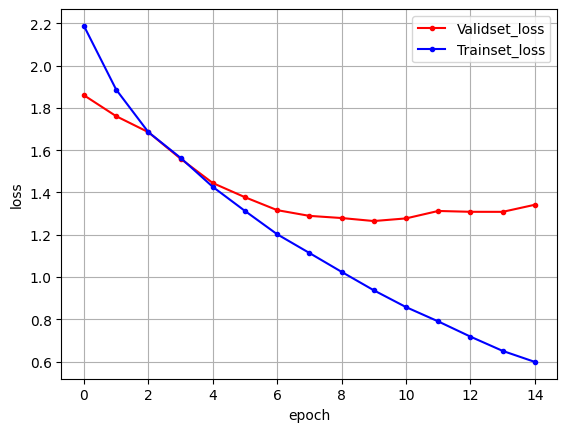

In [22]:
# 학습셋과 검증셋의 오차를 저장합니다.
y_vloss = history.history['val_loss']
y_loss = history.history['loss']

# 그래프로 표현해 보겠습니다.
x_len = np.arange(len(y_loss))
plt.plot(x_len, y_vloss, marker='.', c="red", label='Validset_loss')
plt.plot(x_len, y_loss, marker='.', c="blue", label='Trainset_loss')

# 그래프에 그리드를 주고 레이블을 표시하겠습니다.
plt.legend(loc='upper right')
plt.grid()
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

In [23]:
# 가장 많은 주제 하나로만 답했을 때의 정확도 (비교 기준)
print('가장 많은 주제의 비율: %.4f' % (y_test.sum(axis=0).max() / len(y_test)))

가장 많은 주제의 비율: 0.3620


## 실습
1. **새 리뷰 예측**: 실습 ①의 모델에 직접 만든 리뷰 두세 문장을 넣어 예측해 보세요. 학습 때의 `token`을 써야 합니다. 사전에 없는 단어가 있으면 어떻게 되는지도 확인해 보세요.
2. **순서를 무시하면?**: 로이터 모델의 `LSTM(100)`을 `GlobalAveragePooling1D()`(단어 임베딩의 평균)로 바꿔 테스트 정확도를 비교해 보세요. 이 모델은 단어의 순서를 보지 않습니다.

먼저 직접 해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [24]:
# 직접 작성해 보세요


### 예시 답안

In [25]:
# 1. 새 리뷰 예측 — 실습 ①의 모델과 token을 다시 만든다 (로이터 실습에서 model 이름을 덮어썼기 때문)
tf.keras.utils.set_random_seed(42)
token = Tokenizer()
token.fit_on_texts(docs)
padded_x = pad_sequences(token.texts_to_sequences(docs), 4)
review = Sequential([Embedding(len(token.word_index) + 1, 8), Flatten(), Dense(1, activation='sigmoid')])
review.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
review.fit(padded_x, classes, epochs=200, verbose=0)

for d in ['참 재밌네요', '연기가 지루하네요', '정말 감동적이에요']:
    y = token.texts_to_sequences([d])
    print(d, '→', y, review.predict(pad_sequences(y, 4), verbose=0)[0])

참 재밌네요 → [[4, 2]] [0.5979406]
연기가 지루하네요 → [[19, 18]] [0.15580703]
정말 감동적이에요 → [[]] [0.3499426]


In [26]:
# 2. 순서를 무시하는 모델
tf.keras.utils.set_random_seed(42)
avg = Sequential()
avg.add(Embedding(1000, 100))
avg.add(GlobalAveragePooling1D())
avg.add(Dense(46, activation='softmax'))
avg.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
h2 = avg.fit(X_train, y_train, batch_size=20, epochs=200, validation_split=0.2,
             callbacks=[EarlyStopping(monitor='val_loss', patience=5)], verbose=0)
print('학습한 에포크 수:', len(h2.history['loss']))
print('Test Accuracy (단어 평균): %.4f' % avg.evaluate(X_test, y_test, verbose=0)[1])

학습한 에포크 수: 33
Test Accuracy (단어 평균): 0.7573


## 더 알아보기: `TextVectorization` 층 (부록 B)
`Tokenizer`와 `pad_sequences`가 하던 일을 케라스의 층 하나로 할 수 있습니다. 실습 ①의 리뷰로 확인해 봅니다.
0은 패딩, 1은 사전에 없는 단어(`[UNK]`) 자리이고, 길이는 뒤쪽에 0을 채워 맞춥니다.

In [27]:
vec = TextVectorization(output_sequence_length=4)
vec.adapt(docs)                        # 학습 문장으로 사전 만들기
print([str(w) for w in vec.get_vocabulary()[:6]])
print(vec(docs).numpy()[:3])           # 번호로 바꾸고 길이 4로 맞추기
print(vec(['재밌어요 재미없네요']).numpy())

['', '[UNK]', '한', '추천하고', '최고예요', '참']
[[21  7  0  0]
 [ 4  0  0  0]
 [ 5  9 19 11]]
[[1 1 0 0]]
